In [1]:
import SimpleITK as sitk

In [2]:
flo_file = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_skull_workdir/wt_M_82Z-CF279/coregistered_head.nii.gz"
ref_file = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/reference_image/oriented_image.nii.gz"
ref_mask = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/reference_image/label_for_nl_registration.nii.gz"
target = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_skull_workdir/wt_M_82Z-CF279/nonlin.nii.gz"
target_transf = r"/home/varhai/PRIMUS/data/83_BIOINFORMATICS/Igor/mouse_skull_workdir/wt_M_82Z-CF279/transf.hdf5"

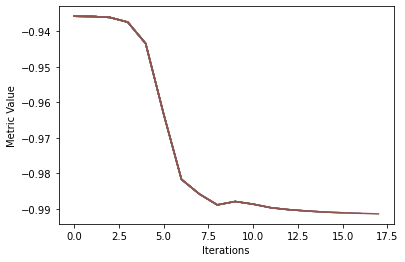

In [ ]:
import matplotlib.pyplot as plt
from IPython import display
def non_rigid_registration(flo_im: str, ref_im: str, out_transform: str, out_image: str,fix_mask: str):
    # Reading
    flo = sitk.ReadImage(flo_im)
    ref = sitk.ReadImage(ref_im)
    print(flo.GetPixelID())
    print(ref.GetPixelID())
    fixed_image_mask = sitk.ReadImage(fix_mask)
    # Ensure both images have the same data type
    ref = sitk.Cast(ref, sitk.sitkFloat32)
    flo = sitk.Cast(flo, sitk.sitkFloat32)
    fixed_image = ref
    moving_image = flo
    # Multi-resolution registration
    registration_method = sitk.ImageRegistrationMethod()
    
    error = []
    # Define a simple callback to monitor registration progress
    def iteration_callback(filter):
        error.append(filter.GetMetricValue())
        if len(error) > 2:
            plt.plot(error)
            plt.xlabel('Iterations')
            plt.ylabel('Metric Value')
            display.clear_output(wait=True)
            display.display(plt.gcf())
        #print('\r{0:.5f}'.format(filter.GetMetricValue()), end='')
        
    # Set the registration parameters
    grid_physical_spacing = [0.5, 0.5, 0.5] # A control point every 50mm
    image_physical_size = [size*spacing for size,spacing in zip(fixed_image.GetSize(), fixed_image.GetSpacing())]
    mesh_size = [int(image_size/grid_spacing + 0.1) \
                 for image_size,grid_spacing in zip(image_physical_size,grid_physical_spacing)]
    
    
    # The starting mesh size will be 1/4 of the original, it will be refined by 
    # the multi-resolution framework.
    mesh_size = [int(sz/4 + 0.5) for sz in mesh_size]
    
    mesh_size = [25,25,25]
    print("im_size", flo.GetSize())
    #return
    print(mesh_size)
    initial_transform = sitk.BSplineTransformInitializer(image1 = fixed_image, 
                                                         transformDomainMeshSize = mesh_size)    
    # Instead of the standard SetInitialTransform we use the BSpline specific method which also
    # accepts the scaleFactors parameter to refine the BSpline mesh. In this case we start with 
    # the given mesh_size at the highest pyramid level then we double it in the next lower level and
    # in the full resolution image we use a mesh that is four times the original size.
    registration_method.SetInitialTransformAsBSpline(initial_transform,
                                                     True
                                                     ,scaleFactors=[1,2,4]
                                                    )

    registration_method.SetMetricAsCorrelation()
    registration_method.SetMetricFixedMask(fixed_image_mask)

    registration_method.SetInterpolator(sitk.sitkLinear)
    
    registration_method.SetShrinkFactorsPerLevel(shrinkFactors = [4,2,1])
    registration_method.SetSmoothingSigmasPerLevel(smoothingSigmas=[1,1,0])
    registration_method.SetOptimizerAsConjugateGradientLineSearch(learningRate=1,numberOfIterations=100,
                                                                  convergenceMinimumValue=1e-2)
    #registration_method.SetOptimizerAsOnePlusOneEvolutionary()
    #registration_method.SetOptimizerAsLBFGS2(solutionAccuracy=1e-4, numberOfIterations=100, deltaConvergenceTolerance=0.0001)
    #registration_method.SetOptimizerScalesFromPhysicalShift()
#     registration_method.SetOptimizerAsLBFGSB(gradientConvergenceTolerance=1e-4,
#                        numberOfIterations=100,
#                        maximumNumberOfCorrections=10,
#                        maximumNumberOfFunctionEvaluations=1000,
#                        costFunctionConvergenceFactor=1e+7)
    
    #registration_method.SetOptimizerAsGradientDescent(learningRate=1,numberOfIterations=100)
    registration_method.AddCommand(sitk.sitkIterationEvent, lambda: iteration_callback(registration_method))
    
    final_transformation = registration_method.Execute(fixed_image, moving_image)
    print('\nOptimizer\'s stopping condition, {0}'.format(registration_method.GetOptimizerStopConditionDescription()))
    print('\nOptimizer\'s final metric value, {0}'.format(registration_method.GetMetricValue()))
    sitk.WriteTransform(final_transformation, out_transform)
    # Save the registered image
    registered_image = sitk.Resample(flo, ref, final_transformation, sitk.sitkLinear, 0.0, ref.GetPixelID())
    sitk.WriteImage(registered_image, out_image, useCompression=True)
    plt.plot(error)
    plt.savefig("")
non_rigid_registration(flo_im=flo_file,ref_im=ref_file,out_transform=target_transf,out_image=target,fix_mask=ref_mask)